# Digital Image Processing Lab - Lab Task 04
## Geometric Transformations with Custom Inputs

**Name:** AFZAAL AHMED
**Roll No:** 2024-SE-2024_SE_40
**Session:** 2024-28 (SE) | **Semester:** Fifth | **Instructor:** Engr. Fahad Nisar
**University of Azad Jammu and Kashmir - Department of Software Engineering**

---


## 1. Setup, limits and constants

In [2]:
import math
import hashlib
import tempfile
from pathlib import Path

import numpy as np
import cv2
import matplotlib.pyplot as plt

print("NumPy", np.__version__, "| OpenCV", cv2.__version__)

# ---------- Paths ----------
IMAGE_PATH = "input_image.png"
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# ---------- Declared (and enforced) limits ----------
MAX_SIDE = 4096            # maximum output width or height in pixels
MAX_PIXELS = 16_000_000    # maximum output width * height
MAX_OFFSET = 100_000       # maximum |tx| or |ty| for translation

# Background used for areas exposed by translation / rotation (RGB black)
BACKGROUND = (0, 0, 0)

# Supported interpolation methods
INTERPOLATIONS = {
    "nearest":  cv2.INTER_NEAREST,
    "bilinear": cv2.INTER_LINEAR,
    "bicubic":  cv2.INTER_CUBIC,
    "lanczos":  cv2.INTER_LANCZOS4,
}
FLIP_DIRECTIONS = ("horizontal", "vertical", "both")

print(f"Limits: max side = {MAX_SIDE}px, max pixels = {MAX_PIXELS:,}, max |offset| = {MAX_OFFSET:,}px")

NumPy 2.5.4 | OpenCV 5.0.0
Limits: max side = 4096px, max pixels = 16,000,000, max |offset| = 100,000px


## 2. Load and validate the image
`load_image` checks that the file exists, that it decodes, and that it has non-zero width and height.
The original is then **locked read-only** and hashed, so we can prove at the end that it was never modified.

Loaded 'input_image.png'
  Width  : 512 px
  Height : 512 px
  Array shape : (512, 512, 3)   (height, width, channels)
  dtype  : uint8 | colour order: RGB
  SHA-256 of original: a8c429c18afa7b0f...


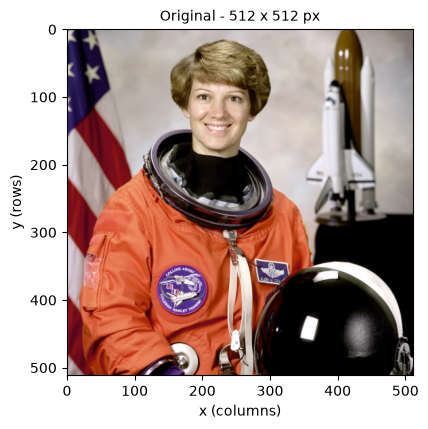

In [3]:
class ValidationError(ValueError):
    """Raised for any invalid image, operation name or parameter value."""


def load_image(path):
    """Load an image file as an RGB uint8 array, validating every step."""
    p = Path(path)
    if not p.is_file():
        raise ValidationError(f"Image file not found: '{path}'")
    try:
        raw = np.fromfile(str(p), dtype=np.uint8)
    except OSError as exc:
        raise ValidationError(f"Could not read '{path}': {exc}") from None
    if raw.size == 0:
        raise ValidationError(f"Image file '{path}' is empty (0 bytes)")
    bgr = cv2.imdecode(raw, cv2.IMREAD_COLOR)          # OpenCV decodes to BGR
    if bgr is None:
        raise ValidationError(f"File '{path}' exists but could not be decoded as an image")
    if bgr.ndim != 3 or bgr.shape[0] == 0 or bgr.shape[1] == 0:
        raise ValidationError(f"Image '{path}' has zero width or height: shape {bgr.shape}")
    return np.ascontiguousarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))   # consistent colour: RGB


original = load_image(IMAGE_PATH)
ORIGINAL_HASH = hashlib.sha256(original.tobytes()).hexdigest()
original.flags.writeable = False        # protect the original from accidental changes

H0, W0 = original.shape[:2]
print(f"Loaded '{IMAGE_PATH}'")
print(f"  Width  : {W0} px")
print(f"  Height : {H0} px")
print(f"  Array shape : {original.shape}   (height, width, channels)")
print(f"  dtype  : {original.dtype} | colour order: RGB")
print(f"  SHA-256 of original: {ORIGINAL_HASH[:16]}...")

plt.figure(figsize=(4.5, 4.5))
plt.imshow(original)
plt.title(f"Original - {W0} x {H0} px", fontsize=10)
plt.xlabel("x (columns)"); plt.ylabel("y (rows)")
plt.show()

### Rejected image loads
A missing file and a file that exists but is not an image both give a clear error instead of a crash.

In [4]:
with tempfile.TemporaryDirectory() as tmp:
    fake = Path(tmp) / "not_an_image.png"
    fake.write_text("this is plain text, not PNG data")
    for bad_path in ["no_such_file.png", str(fake)]:
        try:
            load_image(bad_path)
            print("UNEXPECTEDLY ACCEPTED:", bad_path)
        except ValidationError as err:
            print("REJECTED ->", err)

REJECTED -> Image file not found: 'no_such_file.png'
REJECTED -> File 'C:\Users\afzaa\AppData\Local\Temp\tmpdoo823je\not_an_image.png' exists but could not be decoded as an image


## 3. Validation helpers
These small functions are shared by the notebook's text-input layer **and** by `transform`, so the
rules are written once and applied in both places. Nothing is silently replaced by a default value.

In [5]:
def _as_finite_number(value, name):
    """Return value as a finite float. Accepts numbers and numeric text; rejects everything else."""
    if isinstance(value, (bool, np.bool_)):
        raise ValidationError(f"'{name}' must be a number, not a boolean ({value!r})")
    if isinstance(value, str):
        text = value.strip()
        if text == "":
            raise ValidationError(f"'{name}' is empty - please enter a number")
        try:
            number = float(text)
        except ValueError:
            raise ValidationError(f"'{name}' must be numeric, got {value!r}") from None
    elif isinstance(value, (int, float, np.integer, np.floating)):
        try:
            number = float(value)
        except OverflowError:
            raise ValidationError(f"'{name}' is too large to be used ({value!r})") from None
    else:
        raise ValidationError(f"'{name}' must be numeric, got {type(value).__name__}")
    if math.isnan(number):
        raise ValidationError(f"'{name}' is NaN (not a number)")
    if math.isinf(number):
        raise ValidationError(f"'{name}' is infinite")
    return number


def _as_integer(value, name):
    """Return value as int. Whole numbers only (10 and '10' and 10.0 are fine, 10.5 is not)."""
    number = _as_finite_number(value, name)
    if not float(number).is_integer():
        raise ValidationError(f"'{name}' must be a whole number, got {value!r}")
    return int(number)


def _as_choice(value, name, allowed):
    """Return the lower-cased choice if it is one of `allowed`; otherwise raise."""
    if not isinstance(value, str):
        raise ValidationError(f"'{name}' must be text, one of {list(allowed)}; got {value!r}")
    choice = value.strip().lower()
    if choice not in allowed:
        raise ValidationError(f"Unsupported {name} {value!r}. Supported: {list(allowed)}")
    return choice


_TRUE_WORDS = {"true", "yes", "y", "1"}
_FALSE_WORDS = {"false", "no", "n", "0"}

def _as_bool(value, name):
    """Return a bool from True/False or from yes/no/true/false text."""
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, str):
        word = value.strip().lower()
        if word in _TRUE_WORDS:
            return True
        if word in _FALSE_WORDS:
            return False
    raise ValidationError(f"'{name}' must be True/False (or yes/no), got {value!r}")


def _check_image(image):
    """Validate the image array and return (height, width)."""
    if not isinstance(image, np.ndarray):
        raise ValidationError(f"image must be a NumPy array, got {type(image).__name__}")
    if image.dtype != np.uint8:
        raise ValidationError(f"image must have dtype uint8, got {image.dtype}")
    if image.ndim not in (2, 3) or (image.ndim == 3 and image.shape[2] not in (1, 3, 4)):
        raise ValidationError(f"image must be (H, W) or (H, W, 1/3/4); got shape {image.shape}")
    h, w = image.shape[:2]
    if h == 0 or w == 0:
        raise ValidationError(f"image is empty: width={w}, height={h}")
    return h, w


def _check_output_size(out_w, out_h, what):
    """Reject empty outputs and outputs above the declared maximum size."""
    if out_w < 1 or out_h < 1:
        raise ValidationError(f"{what} would give a {out_w} x {out_h} image; "
                              f"both dimensions must be at least 1 pixel")
    if out_w > MAX_SIDE or out_h > MAX_SIDE:
        raise ValidationError(f"{what} would give a {out_w} x {out_h} image; "
                              f"maximum allowed is {MAX_SIDE} px per side")
    if out_w * out_h > MAX_PIXELS:
        raise ValidationError(f"{what} would give {out_w * out_h:,} pixels; "
                              f"maximum allowed is {MAX_PIXELS:,}")


def _rotated_size(w, h, angle_deg):
    """Size of the smallest canvas that holds the whole image after rotating by angle_deg."""
    a = math.radians(math.fmod(angle_deg, 360.0))
    c, s = abs(math.cos(a)), abs(math.sin(a))
    # the 1e-9 stops exact cases (e.g. 90 deg) from rounding up by one pixel
    return int(math.ceil(w * c + h * s - 1e-9)), int(math.ceil(w * s + h * c - 1e-9))


def translation_matrix(tx, ty):
    """2x3 affine matrix that shifts by (tx, ty)."""
    return np.array([[1.0, 0.0, tx],
                     [0.0, 1.0, ty]])


def rotation_matrix(angle_deg, w, h, expand):
    """2x3 affine matrix that rotates about the image centre. Returns (M, out_w, out_h)."""
    angle = math.fmod(angle_deg, 360.0)
    cx, cy = (w - 1) / 2.0, (h - 1) / 2.0                 # centre in pixel-centre coordinates
    M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)     # positive angle = counter-clockwise
    out_w, out_h = w, h
    if expand:
        out_w, out_h = _rotated_size(w, h, angle)
        M[0, 2] += (out_w - 1) / 2.0 - cx                 # move the centre to the new canvas centre
        M[1, 2] += (out_h - 1) / 2.0 - cy
    return M, out_w, out_h

## 4. The reusable `transform` function
`transform(image, operation, **params)` is the **only** entry point. It validates the image, the operation
name and every parameter, then returns the transformed image (a new array - the input is never changed).

| Operation | Required parameters |
|---|---|
| `scale` | `sx`, `sy`, `interpolation` (`nearest`, `bilinear`, `bicubic`, `lanczos`) |
| `crop` | `left`, `top`, `right`, `bottom` |
| `flip` | `direction` (`horizontal`, `vertical`, `both`) |
| `translate` | `tx`, `ty` |
| `rotate` | `angle` (degrees), `expand` (True/False) |

`translate` and `rotate` are **affine** transforms: they are applied with a 2x3 matrix through `cv2.warpAffine`.

In [6]:
REQUIRED = {
    "scale":     ("sx", "sy", "interpolation"),
    "crop":      ("left", "top", "right", "bottom"),
    "flip":      ("direction",),
    "translate": ("tx", "ty"),
    "rotate":    ("angle", "expand"),
}


def validate_params(image, operation, params):
    """Validate everything and return (operation, cleaned_params). Raises ValidationError."""
    h, w = _check_image(image)

    if not isinstance(operation, str):
        raise ValidationError(f"operation must be text, got {operation!r}")
    op = operation.strip().lower()
    if op not in REQUIRED:
        raise ValidationError(f"Unknown operation {operation!r}. Supported: {list(REQUIRED)}")

    missing = [k for k in REQUIRED[op] if k not in params or params[k] is None]
    if missing:
        raise ValidationError(f"Operation '{op}' is missing required parameter(s): {missing}")
    extra = [k for k in params if k not in REQUIRED[op]]
    if extra:
        raise ValidationError(f"Operation '{op}' got unexpected parameter(s): {extra}. "
                              f"It accepts only {list(REQUIRED[op])}")

    if op == "scale":
        sx = _as_finite_number(params["sx"], "sx")
        sy = _as_finite_number(params["sy"], "sy")
        if sx <= 0 or sy <= 0:
            raise ValidationError(f"Scale factors must be greater than zero, got sx={sx}, sy={sy}")
        interp = _as_choice(params["interpolation"], "interpolation", tuple(INTERPOLATIONS))
        out_w = int(math.floor(w * sx + 0.5))              # round half up
        out_h = int(math.floor(h * sy + 0.5))
        _check_output_size(out_w, out_h, f"Scaling by ({sx}, {sy})")
        return op, dict(sx=sx, sy=sy, interpolation=interp, out_w=out_w, out_h=out_h)

    if op == "crop":
        left = _as_integer(params["left"], "left")
        top = _as_integer(params["top"], "top")
        right = _as_integer(params["right"], "right")
        bottom = _as_integer(params["bottom"], "bottom")
        if not (0 <= left < right <= w):
            raise ValidationError(f"Invalid horizontal range: need 0 <= left < right <= {w}, "
                                  f"got left={left}, right={right}")
        if not (0 <= top < bottom <= h):
            raise ValidationError(f"Invalid vertical range: need 0 <= top < bottom <= {h}, "
                                  f"got top={top}, bottom={bottom}")
        return op, dict(left=left, top=top, right=right, bottom=bottom)

    if op == "flip":
        direction = _as_choice(params["direction"], "flip direction", FLIP_DIRECTIONS)
        return op, dict(direction=direction)

    if op == "translate":
        tx = _as_finite_number(params["tx"], "tx")
        ty = _as_finite_number(params["ty"], "ty")
        if abs(tx) > MAX_OFFSET or abs(ty) > MAX_OFFSET:
            raise ValidationError(f"Offsets must satisfy |tx|, |ty| <= {MAX_OFFSET:,}; got tx={tx}, ty={ty}")
        return op, dict(tx=tx, ty=ty)

    # op == "rotate"
    angle = _as_finite_number(params["angle"], "angle")
    expand = _as_bool(params["expand"], "expand")
    out_w, out_h = (w, h)
    if expand:
        out_w, out_h = _rotated_size(w, h, angle)
        _check_output_size(out_w, out_h, f"Rotating by {angle} deg with expand")
    return op, dict(angle=angle, expand=expand, out_w=out_w, out_h=out_h)


def transform(image, operation, **params):
    """Apply one geometric operation with caller-supplied parameters and return the new image."""
    op, p = validate_params(image, operation, params)
    h, w = image.shape[:2]

    if op == "scale":
        return cv2.resize(image, (p["out_w"], p["out_h"]), interpolation=INTERPOLATIONS[p["interpolation"]])

    if op == "crop":
        return image[p["top"]:p["bottom"], p["left"]:p["right"]].copy()   # right/bottom exclusive

    if op == "flip":
        code_ = {"horizontal": 1, "vertical": 0, "both": -1}[p["direction"]]
        return cv2.flip(image, code_)

    if op == "translate":
        M = translation_matrix(p["tx"], p["ty"])
        return cv2.warpAffine(image, M, (w, h), flags=cv2.INTER_LINEAR,
                              borderMode=cv2.BORDER_CONSTANT, borderValue=BACKGROUND)

    # rotate
    M, out_w, out_h = rotation_matrix(p["angle"], w, h, p["expand"])
    return cv2.warpAffine(image, M, (out_w, out_h), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=BACKGROUND)


print("transform() ready. Supported operations:", list(REQUIRED))

transform() ready. Supported operations: ['scale', 'crop', 'flip', 'translate', 'rotate']


## 5. Display and save helpers
Every figure panel is labelled with the **operation, the parameters and the output size**.
Every result shown here is also saved into the `outputs/` folder.

In [7]:
SAVED = []   # (file name, operation, parameters, output size)


def fmt_params(params):
    return ", ".join(f"{k}={v}" for k, v in params.items())


def save_result(img, name, op, params):
    """Save a result as PNG (converted back to BGR for OpenCV) and remember it."""
    path = OUTPUT_DIR / f"{name}.png"
    bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR) if img.ndim == 3 else img
    ok, buf = cv2.imencode(".png", bgr)
    if not ok:
        raise IOError(f"Could not encode {name}")
    buf.tofile(str(path))
    SAVED.append((path.name, op, fmt_params(params), f"{img.shape[1]} x {img.shape[0]}"))
    return path


def run(op, name=None, **params):
    """Run transform on the original, save the result if a name is given, and return it."""
    result = transform(original, op, **params)
    if name:
        save_result(result, name, op, params)
    return result


def panel(op, params, img):
    """(title, image) pair labelled with operation, parameters and output size."""
    return (f"{op}\n{fmt_params(params)}\noutput: {img.shape[1]} x {img.shape[0]} px", img)


def original_panel():
    return (f"ORIGINAL\n\noutput: {W0} x {H0} px", original)


def show_grid(panels, ncols=3, suptitle=None, interp="antialiased"):
    n = len(panels)
    ncols = min(ncols, n)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 4.6 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (title, img) in zip(axes.ravel(), panels):
        ax.axis("on")
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation=interp)
        else:
            ax.imshow(img, interpolation=interp)
        ax.set_title(title, fontsize=8.5)
        ax.tick_params(labelsize=7)
    if suptitle:
        fig.suptitle(suptitle, fontsize=12, fontweight="bold")
    fig.tight_layout(h_pad=2.5)
    plt.show()

## 6. Custom input: prompts that feed `transform`
The user picks an operation and types its parameters. The text is checked **field by field**
(non-numeric, NaN, infinity, unsupported choices ...) and the user is asked again for just that field.
If `transform` itself rejects the combination (for example an invalid crop region), the error is shown
and the parameters for that operation are asked again. Nothing crashes and nothing is replaced by a hidden default.

`run_interactive_session()` uses the normal notebook `input()` prompt by default.

In [8]:
def field_specs(op, image):
    """(parameter name, kind, prompt text, choices) for each parameter of an operation."""
    h, w = image.shape[:2]
    interp_names = tuple(INTERPOLATIONS)
    specs = {
        "scale": [("sx", "number", "  Horizontal scale factor sx (> 0): ", None),
                  ("sy", "number", "  Vertical scale factor sy (> 0): ", None),
                  ("interpolation", "choice", f"  Interpolation {'/'.join(interp_names)}: ", interp_names)],
        "crop": [("left", "int", f"  left   (0 .. {w - 1}): ", None),
                 ("top", "int", f"  top    (0 .. {h - 1}): ", None),
                 ("right", "int", f"  right  (1 .. {w}, exclusive): ", None),
                 ("bottom", "int", f"  bottom (1 .. {h}, exclusive): ", None)],
        "flip": [("direction", "choice", "  Direction horizontal/vertical/both: ", FLIP_DIRECTIONS)],
        "translate": [("tx", "number", "  Horizontal offset tx in pixels (+ = right): ", None),
                      ("ty", "number", "  Vertical offset ty in pixels (+ = down): ", None)],
        "rotate": [("angle", "number", "  Angle in degrees (+ = counter-clockwise): ", None),
                   ("expand", "bool", "  Expand canvas to fit? (yes/no): ", None)],
    }
    return specs[op]


def parse_field(kind, text, name, choices):
    if kind == "number":
        return _as_finite_number(text, name)
    if kind == "int":
        return _as_integer(text, name)
    if kind == "choice":
        return _as_choice(text, name, choices)
    return _as_bool(text, name)


def collect_params(op, image, input_fn):
    """Ask for each parameter, repeating a field until its text is valid."""
    params = {}
    for name, kind, prompt, choices in field_specs(op, image):
        while True:
            text = input_fn(prompt)
            try:
                params[name] = parse_field(kind, text, name, choices)
                break
            except ValidationError as err:
                print(f"    ERROR: {err}  -> please try again")
    return params


def run_interactive_session(image, input_fn=input, show=True, save=True):
    """Prompt loop: choose an operation, enter parameters, see and save the result. 'q' quits."""
    results = []
    print("Interactive transform session  (type q to quit)")
    try:
        while True:
            op_text = input_fn("Operation (scale / crop / flip / translate / rotate, q = quit): ")
            if op_text.strip().lower() in ("q", "quit", "exit"):
                print("Session finished.")
                break
            try:
                op = _as_choice(op_text, "operation", tuple(REQUIRED))
            except ValidationError as err:
                print(f"    ERROR: {err}  -> please try again")
                continue
            while True:                                  # re-ask until transform accepts the values
                params = collect_params(op, image, input_fn)
                try:
                    result = transform(image, op, **params)
                    break
                except ValidationError as err:
                    print(f"    ERROR from transform: {err}")
                    print("    Please enter the parameters for this operation again.")
            n = len(results) + 1
            print(f"  OK -> {op}({fmt_params(params)}) gave {result.shape[1]} x {result.shape[0]} px")
            if save:
                save_result(result, f"interactive_{n}_{op}", op, params)
            if show:
                show_grid([original_panel(), panel(op, params, result)], ncols=2)
            results.append((op, params, result))
    except EOFError:
        print("(input ended)")
    return results


def make_scripted_input(answers):
    """Stand-in for input() that replays typed answers and echoes them like a real prompt."""
    it = iter(answers)
    def fake_input(prompt=""):
        try:
            ans = next(it)
        except StopIteration:
            raise EOFError from None
        print(f"{prompt}{ans}")
        return ans
    return fake_input

### Live session
Set `INTERACTIVE_LIVE = True` and run the cell below to type your own values. It is `False` by default so the
notebook can run top-to-bottom ("Restart & Run All") without waiting for typing.

In [9]:
INTERACTIVE_LIVE = False      # <- set to True to type your own values

if INTERACTIVE_LIVE:
    live_results = run_interactive_session(original)
else:
    print("Live session skipped (INTERACTIVE_LIVE = False). See the scripted session below for a recorded run.")

Live session skipped (INTERACTIVE_LIVE = False). See the scripted session below for a recorded run.


### Recorded session (typed answers replayed, including mistakes)
The answers below are exactly what a user could type. They include a **non-numeric angle**, an **invalid expand choice**,
an **unknown operation**, a **zero-width crop region** that `transform` rejects, a **NaN scale factor** and an
**unsupported interpolation name**, each followed by corrected values.
The session never crashes and always ends with a valid result.

Interactive transform session  (type q to quit)
Operation (scale / crop / flip / translate / rotate, q = quit): shear
    ERROR: Unsupported operation 'shear'. Supported: ['scale', 'crop', 'flip', 'translate', 'rotate']  -> please try again
Operation (scale / crop / flip / translate / rotate, q = quit): rotate
  Angle in degrees (+ = counter-clockwise): abc
    ERROR: 'angle' must be numeric, got 'abc'  -> please try again
  Angle in degrees (+ = counter-clockwise): -45
  Expand canvas to fit? (yes/no): maybe
    ERROR: 'expand' must be True/False (or yes/no), got 'maybe'  -> please try again
  Expand canvas to fit? (yes/no): yes
  OK -> rotate(angle=-45.0, expand=True) gave 725 x 725 px


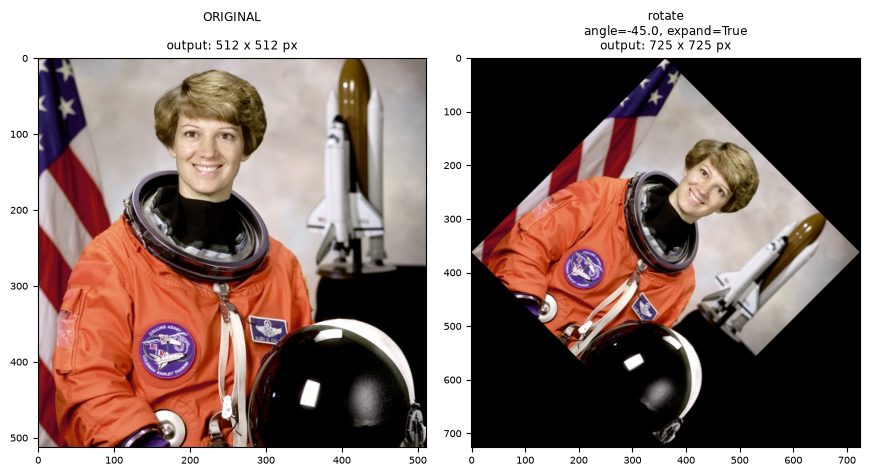

Operation (scale / crop / flip / translate / rotate, q = quit): crop
  left   (0 .. 511): 100
  top    (0 .. 511): 50
  right  (1 .. 512, exclusive): 100
  bottom (1 .. 512, exclusive): 300
    ERROR from transform: Invalid horizontal range: need 0 <= left < right <= 512, got left=100, right=100
    Please enter the parameters for this operation again.
  left   (0 .. 511): 100
  top    (0 .. 511): 50
  right  (1 .. 512, exclusive): 400
  bottom (1 .. 512, exclusive): 300
  OK -> crop(left=100, top=50, right=400, bottom=300) gave 300 x 250 px


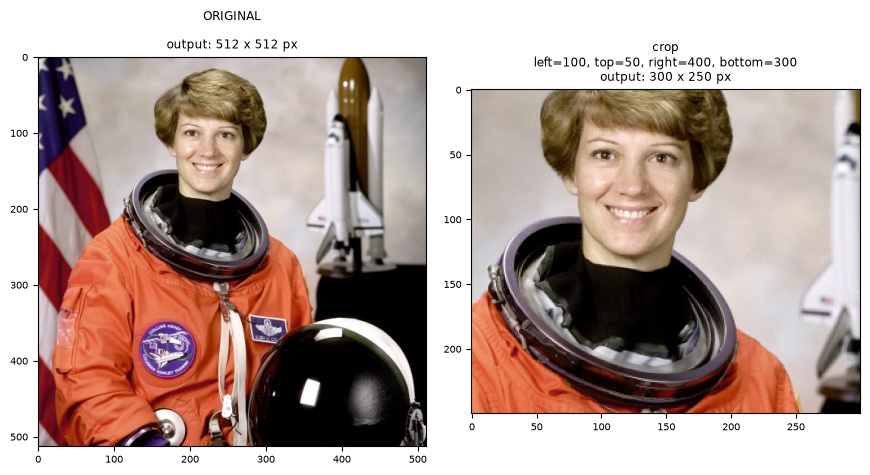

Operation (scale / crop / flip / translate / rotate, q = quit): scale
  Horizontal scale factor sx (> 0): 2.5
  Vertical scale factor sy (> 0): abc
    ERROR: 'sy' must be numeric, got 'abc'  -> please try again
  Vertical scale factor sy (> 0): nan
    ERROR: 'sy' is NaN (not a number)  -> please try again
  Vertical scale factor sy (> 0): 1.5
  Interpolation nearest/bilinear/bicubic/lanczos: cubic
    ERROR: Unsupported interpolation 'cubic'. Supported: ['nearest', 'bilinear', 'bicubic', 'lanczos']  -> please try again
  Interpolation nearest/bilinear/bicubic/lanczos: bicubic
  OK -> scale(sx=2.5, sy=1.5, interpolation=bicubic) gave 1280 x 768 px


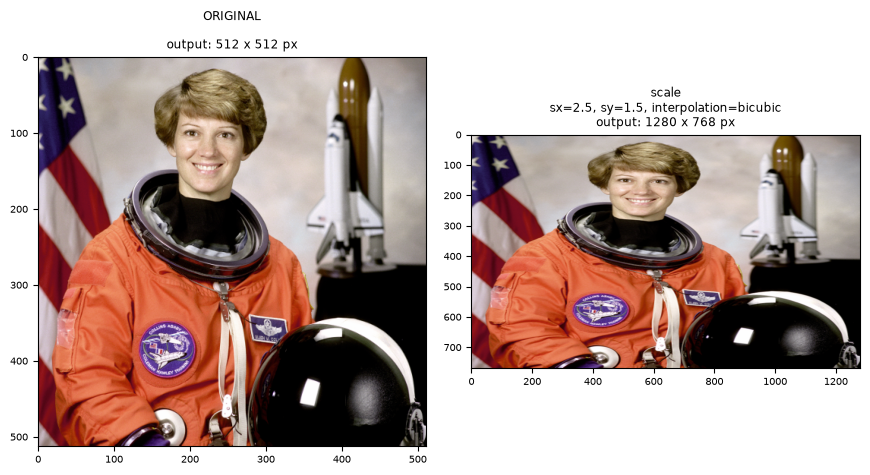

Operation (scale / crop / flip / translate / rotate, q = quit): q
Session finished.

3 valid operations completed in the session.


In [10]:
typed = [
    "shear",              # unknown operation -> rejected
    "rotate",
    "abc",                # non-numeric angle -> rejected, asked again
    "-45",                # negative angle is valid
    "maybe",              # invalid expand choice -> rejected, asked again
    "yes",
    "crop",
    "100", "50", "100", "300",     # left == right -> transform rejects the region
    "100", "50", "400", "300",     # corrected region
    "scale",
    "2.5",                # sx
    "abc", "nan", "1.5",  # sy: non-numeric and NaN rejected, then 1.5 accepted
    "cubic", "bicubic",   # unsupported interpolation rejected, then bicubic accepted
    "q",
]
session_results = run_interactive_session(original, input_fn=make_scripted_input(typed))
print(f"\n{len(session_results)} valid operations completed in the session.")

## 7. Demonstrations with custom values
All values below are passed into `transform` - none are fixed inside it.

### 7.1 Scaling (enlargement, reduction, proportional and non-proportional)

enlarge          : 512x512 -> 768x768  (expected 768x768)  aspect ratio w/h: 1.00 -> 1.00
reduce           : 512x512 -> 256x256  (expected 256x256)  aspect ratio w/h: 1.00 -> 1.00
non-proportional : 512x512 -> 1024x256  (expected 1024x256)  aspect ratio w/h: 1.00 -> 4.00


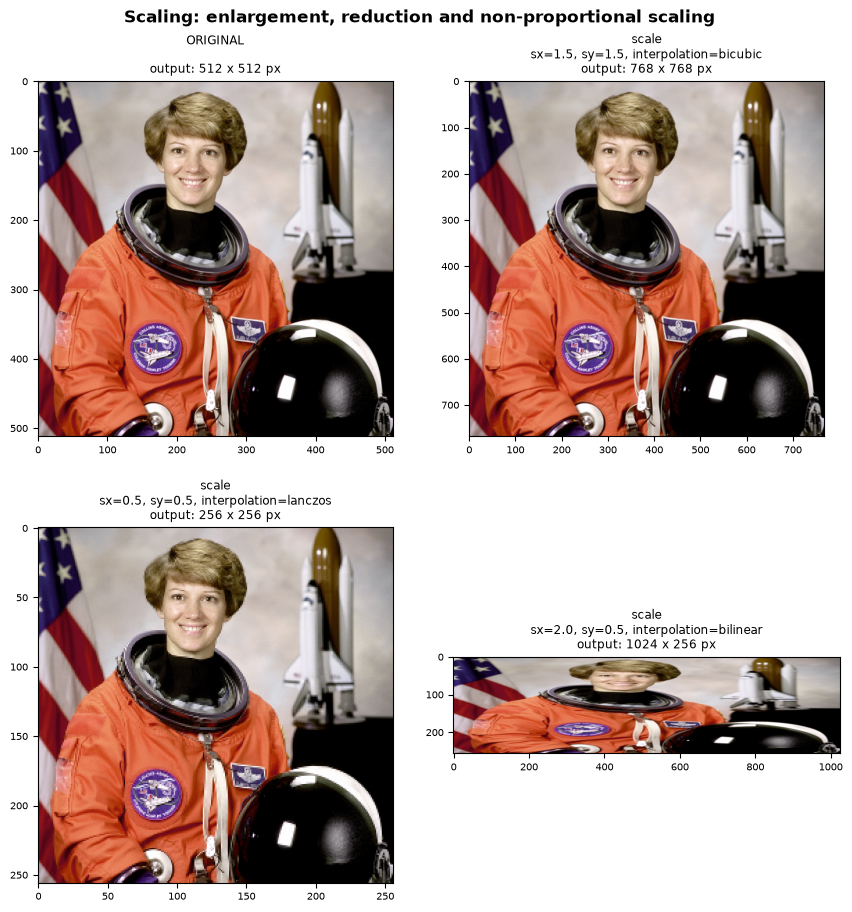

In [11]:
p1 = dict(sx=1.5, sy=1.5, interpolation="bicubic")      # proportional enlargement
p2 = dict(sx=0.5, sy=0.5, interpolation="lanczos")      # proportional reduction
p3 = dict(sx=2.0, sy=0.5, interpolation="bilinear")     # NON-proportional (distorts aspect ratio)

r1 = run("scale", "scale_enlarge_1.5x_bicubic", **p1)
r2 = run("scale", "scale_reduce_0.5x_lanczos", **p2)
r3 = run("scale", "scale_nonproportional_2.0x_0.5y_bilinear", **p3)

for label, pr, r in [("enlarge", p1, r1), ("reduce", p2, r2), ("non-proportional", p3, r3)]:
    exp_w, exp_h = int(math.floor(W0 * pr["sx"] + 0.5)), int(math.floor(H0 * pr["sy"] + 0.5))
    print(f"{label:17s}: {W0}x{H0} -> {r.shape[1]}x{r.shape[0]}  (expected {exp_w}x{exp_h})  "
          f"aspect ratio w/h: {W0 / H0:.2f} -> {r.shape[1] / r.shape[0]:.2f}")

show_grid([original_panel(), panel("scale", p1, r1), panel("scale", p2, r2), panel("scale", p3, r3)],
          ncols=2, suptitle="Scaling: enlargement, reduction and non-proportional scaling")

### 7.2 Cropping
The region is given as `left, top, right, bottom` (right and bottom are exclusive), so the result has
`right - left` columns and `bottom - top` rows.

Crop region {'left': 102, 'top': 64, 'right': 409, 'bottom': 320}
Expected size: 307 x 256  |  actual: 307 x 256


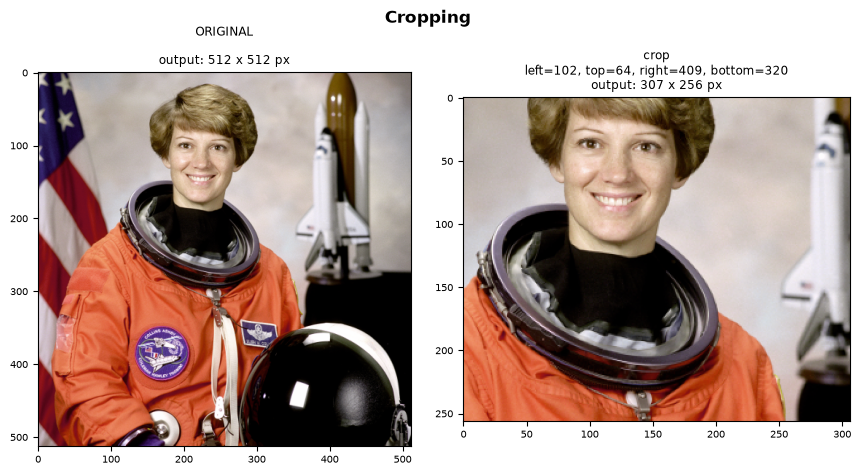

In [12]:
pc = dict(left=W0 // 5, top=H0 // 8, right=W0 * 4 // 5, bottom=H0 * 5 // 8)
rc = run("crop", "crop_custom_region", **pc)
print(f"Crop region {pc}")
print(f"Expected size: {pc['right'] - pc['left']} x {pc['bottom'] - pc['top']}  |  actual: {rc.shape[1]} x {rc.shape[0]}")
show_grid([original_panel(), panel("crop", pc, rc)], ncols=2, suptitle="Cropping")

### 7.3 Flipping (all three directions)

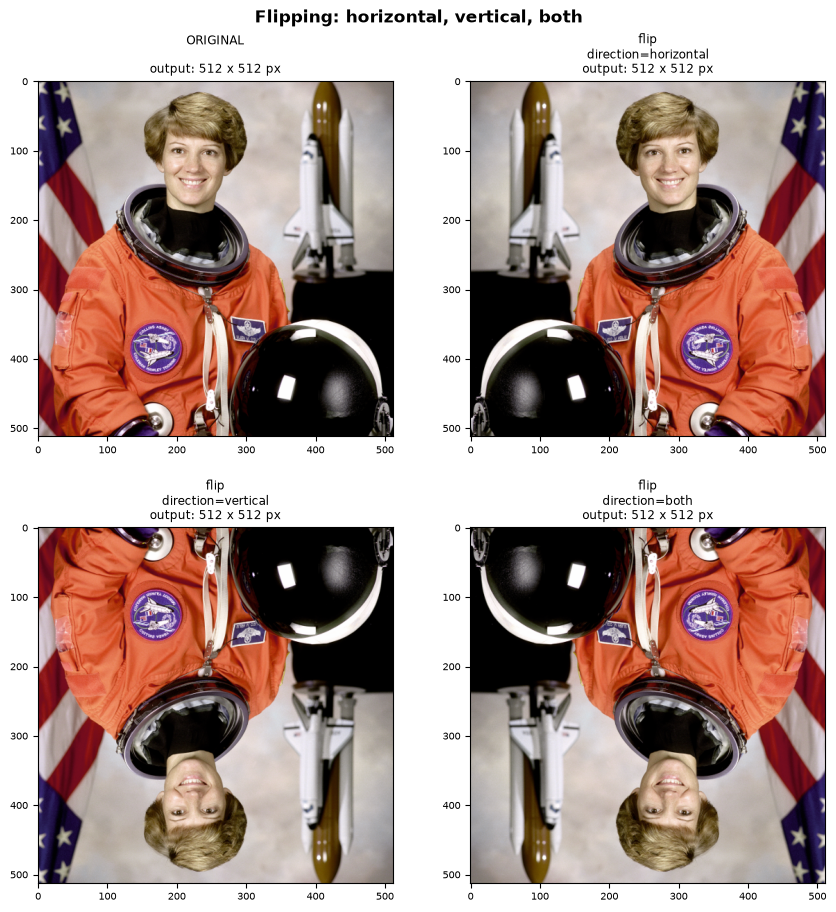

In [13]:
flips = {d: run("flip", f"flip_{d}", direction=d) for d in FLIP_DIRECTIONS}
show_grid([original_panel()] + [panel("flip", dict(direction=d), img) for d, img in flips.items()],
          ncols=2, suptitle="Flipping: horizontal, vertical, both")

### 7.4 Translation (shifts in opposite directions)
The canvas keeps its original size. Pixels pushed past the edge are **clipped** (lost); the opposite
edges are **exposed** and filled with the black background.

tx=+80, ty=+40: kept 203,904 of 262,144 pixels | clipped/exposed area = 58,240 pixels (22.2%)
tx=-80, ty=-40: kept 203,904 of 262,144 pixels | clipped/exposed area = 58,240 pixels (22.2%)
Translation matrix for tx=80, ty=40:
 [[ 1.  0. 80.]
 [ 0.  1. 40.]]


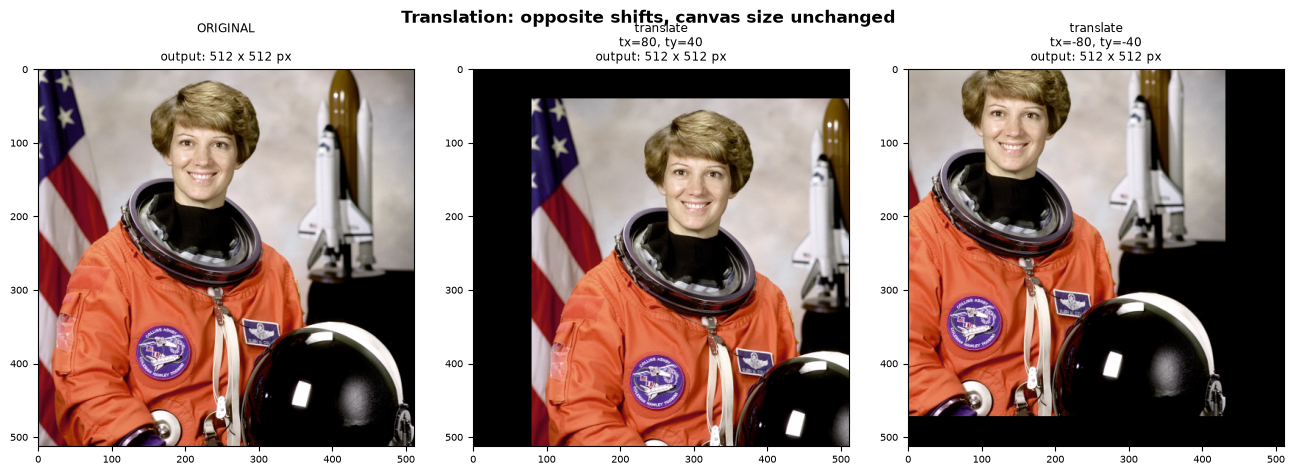

In [14]:
pt1 = dict(tx=80, ty=40)        # right and down
pt2 = dict(tx=-80, ty=-40)      # left and up
rt1 = run("translate", "translate_plus80_plus40", **pt1)
rt2 = run("translate", "translate_minus80_minus40", **pt2)

for pr in (pt1, pt2):
    tx, ty = int(pr["tx"]), int(pr["ty"])
    kept = (W0 - abs(tx)) * (H0 - abs(ty))
    print(f"tx={tx:+d}, ty={ty:+d}: kept {kept:,} of {W0 * H0:,} pixels | "
          f"clipped/exposed area = {W0 * H0 - kept:,} pixels ({100 * (W0 * H0 - kept) / (W0 * H0):.1f}%)")
print("Translation matrix for tx=80, ty=40:\n", translation_matrix(80, 40))

show_grid([original_panel(), panel("translate", pt1, rt1), panel("translate", pt2, rt2)],
          ncols=3, suptitle="Translation: opposite shifts, canvas size unchanged")

### 7.5 Rotation (positive and negative angles, with and without canvas expansion)
Positive angles rotate **counter-clockwise**, negative angles **clockwise**, about the image centre.

angle=+30, expand=False: output 512 x 512 px
angle=+30, expand=True : output 700 x 700 px
angle=-30, expand=False: output 512 x 512 px
angle=-45, expand=True : output 725 x 725 px
Rotation matrix for +30 deg (no expand):
 [[  0.866    0.5    -93.5195]
 [ -0.5      0.866  161.9805]]


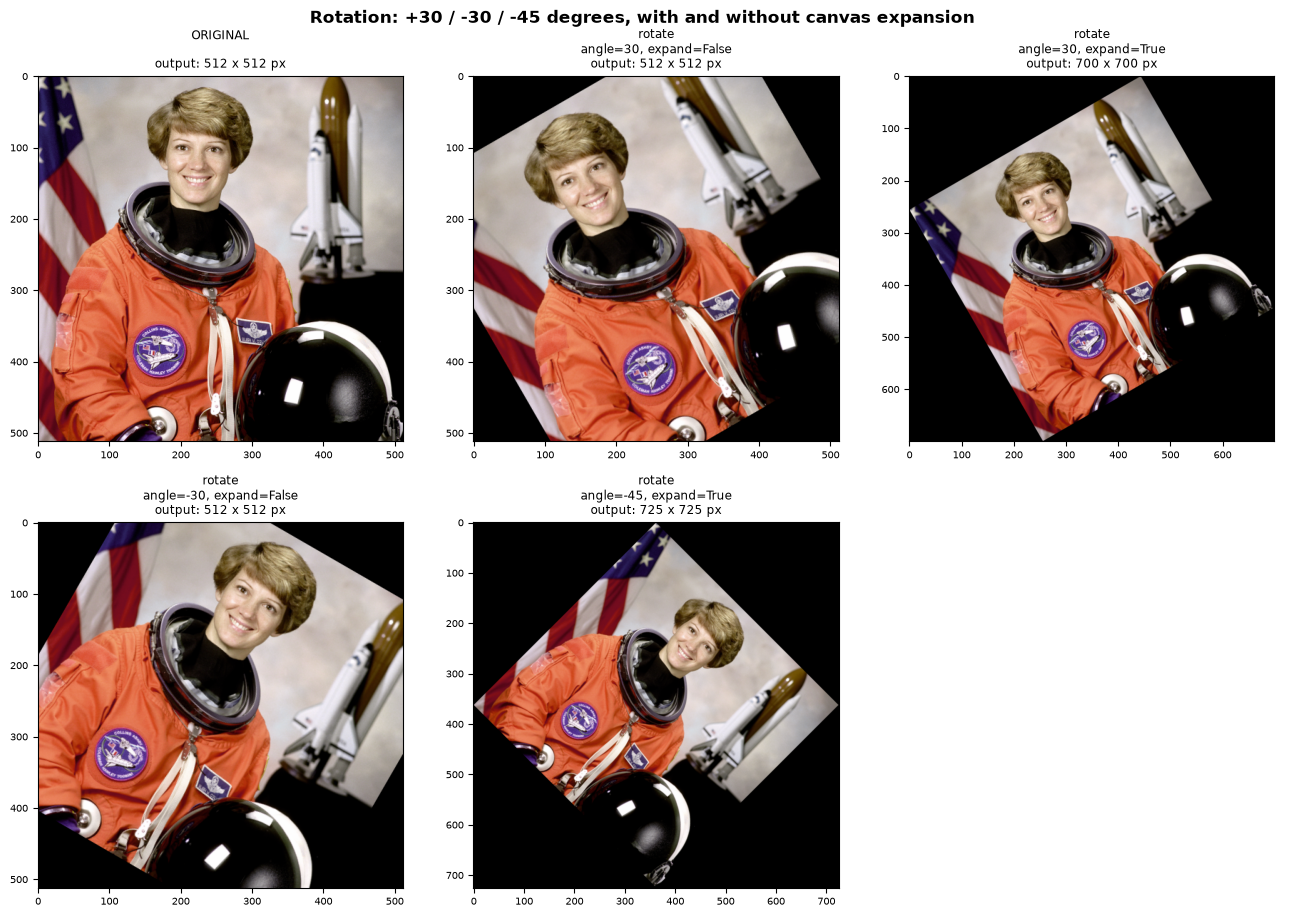

In [15]:
rot_cases = [
    dict(angle=30,  expand=False),
    dict(angle=30,  expand=True),
    dict(angle=-30, expand=False),
    dict(angle=-45, expand=True),
]
rot_results = []
for i, pr in enumerate(rot_cases, 1):
    tag = f"rotate_{'plus' if pr['angle'] > 0 else 'minus'}{abs(int(pr['angle']))}_expand{pr['expand']}"
    rot_results.append(run("rotate", tag, **pr))

for pr, r in zip(rot_cases, rot_results):
    print(f"angle={pr['angle']:+g}, expand={pr['expand']!s:5}: output {r.shape[1]} x {r.shape[0]} px")
print("Rotation matrix for +30 deg (no expand):\n", np.round(rotation_matrix(30, W0, H0, False)[0], 4))

show_grid([original_panel()] + [panel("rotate", pr, r) for pr, r in zip(rot_cases, rot_results)],
          ncols=3, suptitle="Rotation: +30 / -30 / -45 degrees, with and without canvas expansion")

## 8. Interpolation comparison on one enlarged patch
A small, detail-rich patch (chosen automatically as the 48 x 48 window with the highest edge energy) is
enlarged **8x** with each of the four interpolation methods, using `transform`.

Patch: x=144..192, y=352..400 -> 48 x 48 px; enlarged 8x


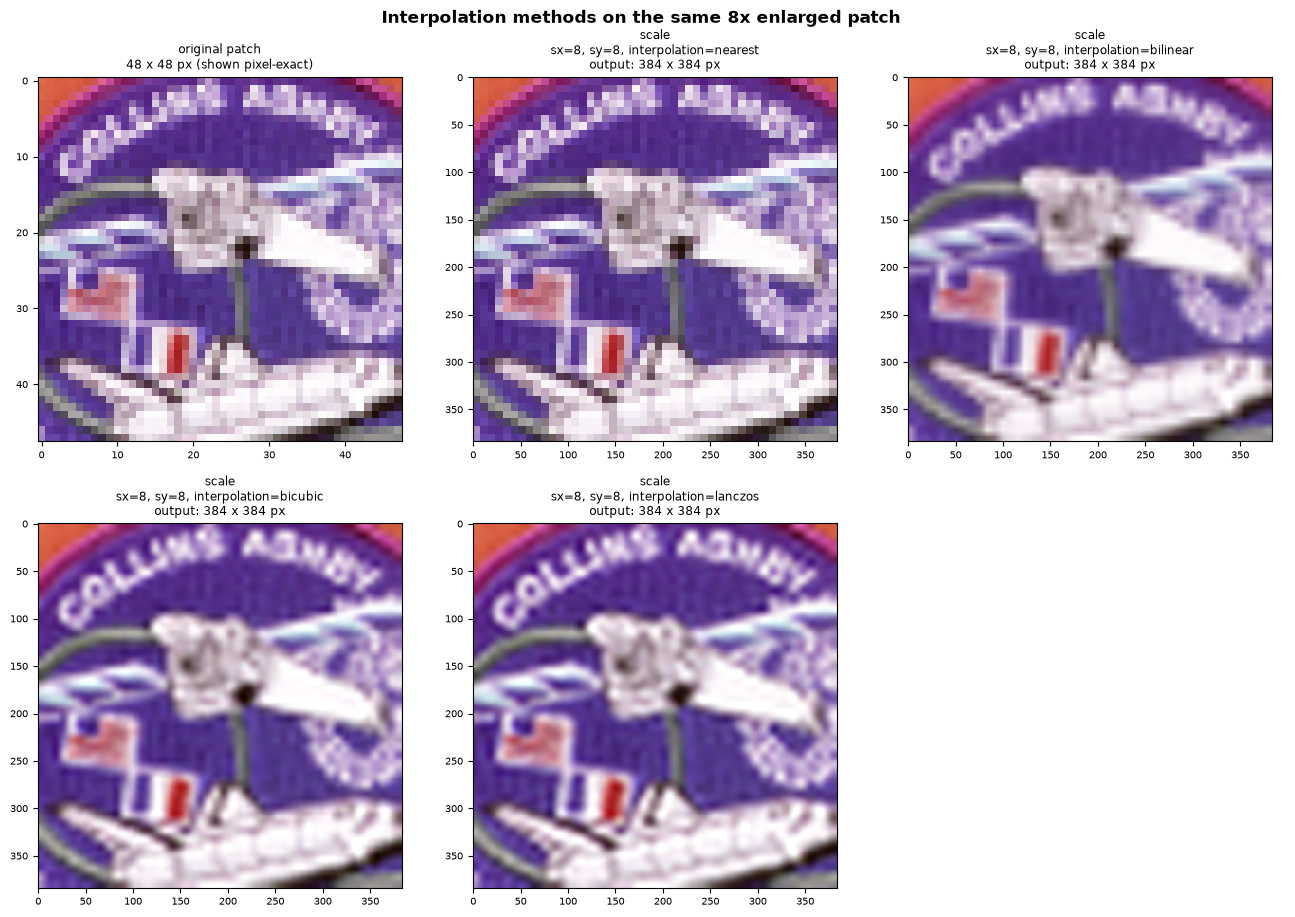


method          size  neighbours identical  largest step  edge strength (p99)  outside orig. range
nearest     384x384                  88.1%           175                482.5                0.00%
bilinear    384x384                  20.5%            22                135.0                0.00%
bicubic     384x384                  17.5%            25                159.2                0.07%
lanczos     384x384                  16.2%            27                163.7                0.06%


In [16]:
def find_detail_patch(img, size=48, stride=16):
    """Top-left corner of the size x size window with the largest Laplacian variance."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    best, best_xy = -1.0, (0, 0)
    for y in range(0, img.shape[0] - size + 1, stride):
        for x in range(0, img.shape[1] - size + 1, stride):
            v = cv2.Laplacian(gray[y:y + size, x:x + size], cv2.CV_64F).var()
            if v > best:
                best, best_xy = v, (x, y)
    return best_xy

PATCH = 48
px, py = find_detail_patch(original, PATCH)
patch = transform(original, "crop", left=px, top=py, right=px + PATCH, bottom=py + PATCH)
print(f"Patch: x={px}..{px + PATCH}, y={py}..{py + PATCH} -> {patch.shape[1]} x {patch.shape[0]} px; enlarged 8x")

enlarged = {m: transform(patch, "scale", sx=8, sy=8, interpolation=m) for m in INTERPOLATIONS}
for m, img in enlarged.items():
    save_result(img, f"interp_{m}_8x", "scale", dict(sx=8, sy=8, interpolation=m))

panels = [(f"original patch\n{PATCH} x {PATCH} px (shown pixel-exact)", patch)]
panels += [panel("scale", dict(sx=8, sy=8, interpolation=m), img) for m, img in enlarged.items()]
show_grid(panels, ncols=3, suptitle="Interpolation methods on the same 8x enlarged patch", interp="nearest")

# Numbers to back up what we see (grey-level versions of the enlarged patches)
gray_patch = cv2.cvtColor(patch, cv2.COLOR_RGB2GRAY)
lo, hi = int(gray_patch.min()), int(gray_patch.max())
print(f"\n{'method':10s} {'size':>9s} {'neighbours identical':>21s} {'largest step':>13s} "
      f"{'edge strength (p99)':>20s} {'outside orig. range':>20s}")
for m, img in enlarged.items():
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float64)
    step = np.abs(np.diff(g, axis=1))                                   # jump between horizontal neighbours
    grad = np.hypot(cv2.Sobel(g, cv2.CV_64F, 1, 0), cv2.Sobel(g, cv2.CV_64F, 0, 1))
    outside = 100.0 * np.mean((g < lo) | (g > hi))                      # overshoot beyond the patch's own range
    print(f"{m:10s} {img.shape[1]:>4d}x{img.shape[0]:<4d} {100 * np.mean(step == 0):>20.1f}% {step.max():>13.0f} "
          f"{np.percentile(grad, 99):>20.1f} {outside:>19.2f}%")

### Observations: visible differences between the interpolation methods
* **Nearest-neighbour** copies the closest source pixel, so every original pixel becomes a hard 8 x 8 block. The result is
  blocky with staircase edges and no new colours are created (about 88% of horizontal neighbours are identical).
  Its large "edge strength" in the table is an artefact of those abrupt block jumps, not real sharpness.
  It is the fastest method and is useful when the pixel grid must stay visible.
* **Bilinear** averages the 4 nearest pixels. The blocks disappear and the picture looks smooth, but fine edges
  (the lettering and the stripes) become soft. It has the weakest real edge strength and never overshoots the original
  value range (0% outside it).
* **Bicubic** uses a 4 x 4 neighbourhood. Edges are visibly crisper than bilinear while staying smooth. The price is a
  little overshoot (a few pixels fall outside the original range, seen as faint halos next to strong edges).
* **Lanczos** uses an 8 x 8 neighbourhood and gives the crispest edges of the smooth methods, with the same kind of slight
  overshoot/ringing as bicubic. On this patch bicubic and Lanczos look very similar; both are clearly sharper than bilinear.

**Rule of thumb:** nearest for pixel-exact enlargements, bilinear for speed and smoothness, bicubic as a good default for
enlarging photos, Lanczos when the sharpest result matters.

## 9. Input validation: rejected inputs
Every case below must be **rejected with a clear message** (no crash). At least one case per operation is shown,
including an unsupported flip direction and non-numeric / non-finite rotation angles.

In [17]:
rejected_cases = [
    # ---- scale ----
    ("scale", dict(sx=0, sy=1, interpolation="bilinear"),            "zero scale factor"),
    ("scale", dict(sx=-2, sy=1, interpolation="bilinear"),           "negative scale factor"),
    ("scale", dict(sx=1, sy="abc", interpolation="bilinear"),        "non-numeric factor"),
    ("scale", dict(sx=float("nan"), sy=1, interpolation="bilinear"), "NaN factor"),
    ("scale", dict(sx=1, sy=float("inf"), interpolation="bilinear"), "infinite factor"),
    ("scale", dict(sx=1, sy=1, interpolation="cubic"),               "unsupported interpolation"),
    ("scale", dict(sx=0.0005, sy=0.0005, interpolation="nearest"),   "output would be 0 x 0 pixels"),
    ("scale", dict(sx=100, sy=100, interpolation="nearest"),         "output above maximum size"),
    ("scale", dict(sx=2, sy=2),                                      "missing interpolation"),
    # ---- crop ----
    ("crop", dict(left=100, top=0, right=100, bottom=50),            "left == right (empty width)"),
    ("crop", dict(left=0, top=0, right=W0 + 1, bottom=50),           "right beyond image width"),
    ("crop", dict(left=-5, top=0, right=50, bottom=50),              "negative left"),
    ("crop", dict(left=0, top=10.5, right=50, bottom=50),            "non-integer coordinate"),
    ("crop", dict(left="x", top=0, right=50, bottom=50),             "non-numeric coordinate"),
    ("crop", dict(left=0, top=0, right=50, bottom=H0 + 10),          "bottom beyond image height"),
    ("crop", dict(left=0, top=80, right=50, bottom=40),              "top > bottom"),
    # ---- flip ----
    ("flip", dict(direction="diagonal"),                             "unsupported direction"),
    ("flip", dict(direction=1),                                      "direction is not text"),
    ("flip", dict(),                                                 "missing direction"),
    # ---- translate ----
    ("translate", dict(tx="abc", ty=0),                              "non-numeric tx"),
    ("translate", dict(tx=0, ty=float("inf")),                       "infinite ty"),
    ("translate", dict(tx=float("nan"), ty=0),                       "NaN tx"),
    ("translate", dict(tx=10),                                       "missing ty"),
    ("translate", dict(tx=10**9, ty=0),                              "offset above declared maximum"),
    # ---- rotate ----
    ("rotate", dict(angle="abc", expand=False),                      "non-numeric angle"),
    ("rotate", dict(angle=float("nan"), expand=False),               "NaN angle"),
    ("rotate", dict(angle=float("inf"), expand=True),                "infinite angle"),
    ("rotate", dict(angle=30, expand="maybe"),                       "invalid expand choice"),
    ("rotate", dict(angle=30),                                       "missing expand"),
    # ---- general ----
    ("shear", dict(),                                                "unknown operation"),
    ("flip", dict(direction="horizontal", angle=5),                  "unexpected extra parameter"),
]

n_ok = 0
for op, pr, why in rejected_cases:
    try:
        transform(original, op, **pr)
        print(f"!! ACCEPTED (should have been rejected): {op} {pr}")
    except ValidationError as err:
        n_ok += 1
        print(f"[REJECTED] {op:9s} | {why}\n           -> {err}")

# Bad images
bad_images = [
    ("None instead of an image", None),
    ("empty array (0 rows)", np.zeros((0, 10, 3), dtype=np.uint8)),
    ("float image (not uint8)", np.zeros((10, 10, 3), dtype=np.float32)),
]
for why, img in bad_images:
    try:
        transform(img, "flip", direction="horizontal")
        print(f"!! ACCEPTED (should have been rejected): {why}")
    except ValidationError as err:
        n_ok += 1
        print(f"[REJECTED] image     | {why}\n           -> {err}")

total = len(rejected_cases) + len(bad_images)
print(f"\n{n_ok} of {total} invalid inputs were rejected with a clear message.")

[REJECTED] scale     | zero scale factor
           -> Scale factors must be greater than zero, got sx=0.0, sy=1.0
[REJECTED] scale     | negative scale factor
           -> Scale factors must be greater than zero, got sx=-2.0, sy=1.0
[REJECTED] scale     | non-numeric factor
           -> 'sy' must be numeric, got 'abc'
[REJECTED] scale     | NaN factor
           -> 'sx' is NaN (not a number)
[REJECTED] scale     | infinite factor
           -> 'sy' is infinite
[REJECTED] scale     | unsupported interpolation
           -> Unsupported interpolation 'cubic'. Supported: ['nearest', 'bilinear', 'bicubic', 'lanczos']
[REJECTED] scale     | output would be 0 x 0 pixels
           -> Scaling by (0.0005, 0.0005) would give a 0 x 0 image; both dimensions must be at least 1 pixel
[REJECTED] scale     | output above maximum size
           -> Scaling by (100.0, 100.0) would give a 51200 x 51200 image; maximum allowed is 4096 px per side
[REJECTED] scale     | missing interpolation
           -

### Valid boundary inputs that must be accepted
Zero values, negative values and exact limits are **valid** and must not be rejected.

In [18]:
boundary_cases = [
    ("crop", dict(left=0, top=0, right=W0, bottom=H0),                       "whole image"),
    ("crop", dict(left=W0 - 1, top=H0 - 1, right=W0, bottom=H0),             "single pixel (last pixel)"),
    ("scale", dict(sx=1 / W0, sy=1 / H0, interpolation="nearest"),           "smallest valid output, 1 x 1"),
    ("scale", dict(sx="1.5", sy="1.5", interpolation="BILINEAR"),            "numeric text, upper-case name"),
    ("translate", dict(tx=0, ty=0),                                          "zero offsets"),
    ("translate", dict(tx=-25, ty=0),                                        "negative offset"),
    ("translate", dict(tx=W0 + 50, ty=0),                                    "shift fully off-canvas (all background)"),
    ("rotate", dict(angle=0, expand=False),                                  "zero angle"),
    ("rotate", dict(angle=-90, expand=True),                                 "negative angle"),
    ("rotate", dict(angle=720, expand=True),                                 "two full turns"),
    ("rotate", dict(angle="30", expand="yes"),                               "numeric text / yes"),
    ("flip", dict(direction="Both"),                                         "mixed-case direction"),
]
print(f"{'operation':10s} {'case':42s} {'output (w x h)':>14s}")
for op, pr, why in boundary_cases:
    out = transform(original, op, **pr)
    print(f"{op:10s} {why:42s} {out.shape[1]:>6d} x {out.shape[0]:<5d}")

operation  case                                       output (w x h)
crop       whole image                                   512 x 512  
crop       single pixel (last pixel)                       1 x 1    
scale      smallest valid output, 1 x 1                    1 x 1    
scale      numeric text, upper-case name                 768 x 768  
translate  zero offsets                                  512 x 512  
translate  negative offset                               512 x 512  
translate  shift fully off-canvas (all background)       512 x 512  
rotate     zero angle                                    512 x 512  
rotate     negative angle                                512 x 512  
rotate     two full turns                                512 x 512  
rotate     numeric text / yes                            700 x 700  
flip       mixed-case direction                          512 x 512  


## 10. Identity checks and correctness checks
Identity cases must give back the **exact same pixels and the same size**. Extra checks compare
`transform` against independent NumPy results.

In [19]:
def check_table(rows, title):
    print(title)
    print(f"{'Check':44s} {'Expected':34s} {'Actual':36s} {'Result'}")
    print("-" * 125)
    passed = 0
    for name, expected, actual, ok in rows:
        passed += ok
        print(f"{name:44s} {expected:34s} {actual:36s} {'Pass' if ok else 'FAIL'}")
    print(f"\n{passed} of {len(rows)} checks passed.\n")
    return passed == len(rows)


def identity_row(name, op, **pr):
    out = transform(original, op, **pr)
    same_shape = out.shape == original.shape
    same_pixels = same_shape and np.array_equal(out, original)
    diff = int(np.abs(out.astype(int) - original.astype(int)).max()) if same_shape else -1
    actual = f"shape {out.shape[1]}x{out.shape[0]}, max diff {diff}"
    return (name, "identical pixels, same size", actual, same_pixels)


identity_rows = [identity_row(f"scale 1.0 x 1.0, {m}", "scale", sx=1, sy=1, interpolation=m) for m in INTERPOLATIONS]
identity_rows += [
    identity_row("translate tx=0, ty=0", "translate", tx=0, ty=0),
    identity_row("translate tx=-0.0, ty=0", "translate", tx=-0.0, ty=0),
    identity_row("rotate 0 deg, expand=False", "rotate", angle=0, expand=False),
    identity_row("rotate 0 deg, expand=True", "rotate", angle=0, expand=True),
    identity_row("rotate 360 deg, expand=False", "rotate", angle=360, expand=False),
    identity_row("crop whole image", "crop", left=0, top=0, right=W0, bottom=H0),
]
ok_identity = check_table(identity_rows, "IDENTITY CHECKS")

IDENTITY CHECKS
Check                                        Expected                           Actual                               Result
-----------------------------------------------------------------------------------------------------------------------------
scale 1.0 x 1.0, nearest                     identical pixels, same size        shape 512x512, max diff 0            Pass
scale 1.0 x 1.0, bilinear                    identical pixels, same size        shape 512x512, max diff 0            Pass
scale 1.0 x 1.0, bicubic                     identical pixels, same size        shape 512x512, max diff 0            Pass
scale 1.0 x 1.0, lanczos                     identical pixels, same size        shape 512x512, max diff 0            Pass
translate tx=0, ty=0                         identical pixels, same size        shape 512x512, max diff 0            Pass
translate tx=-0.0, ty=0                      identical pixels, same size        shape 512x512, max diff 0            Pass
ro

In [20]:
def rows_equal(name, expected, got, want, tol=0):
    same = got.shape == want.shape
    diff = int(np.abs(got.astype(int) - want.astype(int)).max()) if same else -1
    return (name, expected, f"shape ok={same}, max diff {diff}", same and diff <= tol)

rows = []
rows.append(rows_equal("flip horizontal vs NumPy [:, ::-1]", "equals img[:, ::-1]",
                       transform(original, "flip", direction="horizontal"), original[:, ::-1]))
rows.append(rows_equal("flip vertical vs NumPy [::-1]", "equals img[::-1]",
                       transform(original, "flip", direction="vertical"), original[::-1]))
rows.append(rows_equal("flip both vs NumPy [::-1, ::-1]", "equals img[::-1, ::-1]",
                       transform(original, "flip", direction="both"), original[::-1, ::-1]))
rows.append(rows_equal("flip horizontal twice", "back to the original",
                       transform(transform(original, "flip", direction="horizontal"), "flip", direction="horizontal"),
                       original))
rows.append(rows_equal("crop vs NumPy slice [50:200, 30:150]", "equals img[50:200, 30:150]",
                       transform(original, "crop", left=30, top=50, right=150, bottom=200), original[50:200, 30:150]))

# translation: pixel (x, y) must land at (x + tx, y + ty) and the exposed strips must be background
tx, ty = 60, -35
moved = transform(original, "translate", tx=tx, ty=ty)
x0, x1 = max(0, tx), min(W0, W0 + tx)
y0, y1 = max(0, ty), min(H0, H0 + ty)
moved_ok = np.array_equal(moved[y0:y1, x0:x1], original[y0 - ty:y1 - ty, x0 - tx:x1 - tx])
rows.append(("translate tx=60, ty=-35: pixel mapping", "moved[y+ty, x+tx] == orig[y, x]",
             f"mapping identical = {moved_ok}", moved_ok))
bg_ok = bool((moved[:, :tx] == 0).all() and (moved[y1:, :] == 0).all())
rows.append(("translate: exposed strips are background", "left 60 cols & bottom 35 rows black",
             f"all black = {bg_ok}", bg_ok))

# rotation direction and sizes: +90 deg (counter-clockwise) must match np.rot90 with k=1
r90 = transform(original, "rotate", angle=90, expand=True)
rows.append(rows_equal("rotate +90 expand vs np.rot90(k=1) (CCW)", "matches within 1 grey level",
                       r90, np.rot90(original, 1), tol=1))
r180 = transform(original, "rotate", angle=180, expand=True)
rows.append(rows_equal("rotate 180 expand vs np.rot90(k=2)", "matches within 1 grey level",
                       r180, np.rot90(original, 2), tol=1))
rm90 = transform(original, "rotate", angle=-90, expand=True)
rows.append(rows_equal("rotate -90 expand vs np.rot90(k=-1) (CW)", "matches within 1 grey level",
                       rm90, np.rot90(original, -1), tol=1))

# scale output size
s = transform(original, "scale", sx=1.5, sy=0.75, interpolation="bilinear")
exp_w, exp_h = int(W0 * 1.5 + 0.5), int(H0 * 0.75 + 0.5)
rows.append(("scale 1.5 x 0.75: output size", f"{exp_w} x {exp_h}", f"{s.shape[1]} x {s.shape[0]}",
             (s.shape[1], s.shape[0]) == (exp_w, exp_h)))

ok_correct = check_table(rows, "CORRECTNESS CHECKS (independent NumPy comparison)")

CORRECTNESS CHECKS (independent NumPy comparison)
Check                                        Expected                           Actual                               Result
-----------------------------------------------------------------------------------------------------------------------------
flip horizontal vs NumPy [:, ::-1]           equals img[:, ::-1]                shape ok=True, max diff 0            Pass
flip vertical vs NumPy [::-1]                equals img[::-1]                   shape ok=True, max diff 0            Pass
flip both vs NumPy [::-1, ::-1]              equals img[::-1, ::-1]             shape ok=True, max diff 0            Pass
flip horizontal twice                        back to the original               shape ok=True, max diff 0            Pass
crop vs NumPy slice [50:200, 30:150]         equals img[50:200, 30:150]         shape ok=True, max diff 0            Pass
translate tx=60, ty=-35: pixel mapping       moved[y+ty, x+tx] == orig[y, x]    mapping id

## 11. Short explanations (with evidence)

In [21]:
# --- Image coordinates vs array indexing ---
x, y = 120, 40
print("Pixel at image coordinate (x=120, y=40) is read as  original[y, x] =", original[y, x])
print("original.shape =", original.shape, "-> (height, width, channels): ROW first, COLUMN second.")
crop_demo = transform(original, "crop", left=10, top=20, right=210, bottom=120)   # 200 wide, 100 tall
print("Crop is 200 px wide and 100 px tall -> array shape", crop_demo.shape,
      "(rows=100, cols=200), while cv2.resize/warpAffine take sizes as (width, height).")

Pixel at image coordinate (x=120, y=40) is read as  original[y, x] = [193 186 174]
original.shape = (512, 512, 3) -> (height, width, channels): ROW first, COLUMN second.
Crop is 200 px wide and 100 px tall -> array shape (100, 200, 3) (rows=100, cols=200), while cv2.resize/warpAffine take sizes as (width, height).


**Image coordinates vs array indexing.** An image coordinate is written `(x, y)`: `x` runs to the right (columns) and
`y` runs downwards (rows), with the origin at the top-left pixel. A NumPy array is indexed the other way round,
`img[row, column] = img[y, x]`, and its shape is `(height, width, channels)`. OpenCV functions such as `resize` and
`warpAffine` take sizes as `(width, height)`, so mixing the two orders is a common source of bugs. A crop with
`left, top, right, bottom` is the slice `img[top:bottom, left:right]` (right and bottom exclusive).

In [22]:
# --- Aspect-ratio distortion ---
for label, pr in [("proportional  sx=sy=1.5", dict(sx=1.5, sy=1.5)),
                  ("non-proportional sx=2.0, sy=0.5", dict(sx=2.0, sy=0.5))]:
    out = transform(original, "scale", interpolation="bilinear", **pr)
    print(f"{label:34s} output {out.shape[1]}x{out.shape[0]}  width/height = {out.shape[1] / out.shape[0]:.2f} "
          f"(original {W0 / H0:.2f})")

proportional  sx=sy=1.5            output 768x768  width/height = 1.00 (original 1.00)
non-proportional sx=2.0, sy=0.5    output 1024x256  width/height = 4.00 (original 1.00)


**Aspect-ratio distortion.** The aspect ratio is `width / height`. It is preserved only when `sx == sy`.
With `sx != sy` the image is stretched in one direction (here 4 times wider relative to its height), so circles
become ellipses and faces look squashed or stretched.

In [23]:
# --- Rotation canvas expansion ---
print(f"{'angle':>6s} {'formula W = w|cos| + h|sin|, H = w|sin| + h|cos|':>56s} {'actual expanded size':>22s} {'same-size canvas':>18s}")
for ang in (30, -30, 45, 90):
    a = math.radians(abs(ang))
    fw, fh = W0 * math.cos(a) + H0 * math.sin(a), W0 * math.sin(a) + H0 * math.cos(a)
    big = transform(original, "rotate", angle=ang, expand=True)
    same = transform(original, "rotate", angle=ang, expand=False)
    print(f"{ang:>6d} {fw:>28.1f} x {fh:<25.1f} {big.shape[1]:>10d} x {big.shape[0]:<9d} {same.shape[1]:>8d} x {same.shape[0]}")

 angle         formula W = w|cos| + h|sin|, H = w|sin| + h|cos|   actual expanded size   same-size canvas
    30                        699.4 x 699.4                            700 x 700            512 x 512
   -30                        699.4 x 699.4                            700 x 700            512 x 512
    45                        724.1 x 724.1                            725 x 725            512 x 512
    90                        512.0 x 512.0                            512 x 512            512 x 512


**Rotation canvas expansion.** Rotating about the centre while keeping the canvas the same size cuts off the corners
of the image (they swing outside the canvas) and exposes background in the new corners. With `expand=True` the canvas
grows to `W = w|cos(a)| + h|sin(a)|` by `H = w|sin(a)| + h|cos(a)|` (rounded up), so nothing is lost, at the cost of a
larger image with more background. The table above shows the formula matches the real output size. A positive angle
rotates **counter-clockwise** (verified against `np.rot90` in section 10).

In [24]:
# --- Translation clipping ---
tx, ty = 150, 100
moved = transform(original, "translate", tx=tx, ty=ty)
lost_cols, lost_rows = tx, ty
kept = (W0 - tx) * (H0 - ty)
print(f"tx={tx}, ty={ty}: output is still {moved.shape[1]} x {moved.shape[0]} (canvas unchanged)")
print(f"Kept {kept:,} original pixels; {W0 * H0 - kept:,} pixels of the canvas are exposed background; "
      f"the last {tx} columns and {ty} rows of the original were clipped.")
print("Exposed left strip and top strip are all black:", bool((moved[:, :tx] == 0).all() and (moved[:ty, :] == 0).all()))

tx=150, ty=100: output is still 512 x 512 (canvas unchanged)
Kept 149,144 original pixels; 113,000 pixels of the canvas are exposed background; the last 150 columns and 100 rows of the original were clipped.
Exposed left strip and top strip are all black: True


**Translation clipping.** Translation keeps the canvas at its original size. Pixels pushed beyond the right/bottom edge
(for positive `tx`, `ty`) or the left/top edge (for negative values) are **clipped**, meaning they are lost for good.
The opposite sides of the canvas become **exposed background** (black here) because there is no source pixel for them.
A shift larger than the image size moves everything off-canvas and leaves only background.

## 12. Final checks and saved files

In [25]:
unchanged = hashlib.sha256(original.tobytes()).hexdigest() == ORIGINAL_HASH
print("Original image unchanged after every operation:", unchanged, "(read-only flag:", not original.flags.writeable, ")")
print("Identity checks all passed   :", ok_identity)
print("Correctness checks all passed:", ok_correct)

print(f"\nSaved transformed results in '{OUTPUT_DIR}/' ({len(SAVED)} files):")
print(f"{'file':52s} {'operation':10s} {'size':>11s}  parameters")
for fname, op, prm, size in SAVED:
    print(f"{fname:52s} {op:10s} {size:>11s}  {prm}")

Original image unchanged after every operation: True (read-only flag: True )
Identity checks all passed   : True
Correctness checks all passed: True

Saved transformed results in 'outputs/' (20 files):
file                                                 operation         size  parameters
interactive_1_rotate.png                             rotate       725 x 725  angle=-45.0, expand=True
interactive_2_crop.png                               crop         300 x 250  left=100, top=50, right=400, bottom=300
interactive_3_scale.png                              scale       1280 x 768  sx=2.5, sy=1.5, interpolation=bicubic
scale_enlarge_1.5x_bicubic.png                       scale        768 x 768  sx=1.5, sy=1.5, interpolation=bicubic
scale_reduce_0.5x_lanczos.png                        scale        256 x 256  sx=0.5, sy=0.5, interpolation=lanczos
scale_nonproportional_2.0x_0.5y_bilinear.png         scale       1024 x 256  sx=2.0, sy=0.5, interpolation=bilinear
crop_custom_region.png        